## Chapter 5 Task

### Import Libraries

In [1]:
import seaborn as sns

### Load Dataset

In [3]:
titanic_data = sns.load_dataset("titanic")
titanic_data

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
886,0,2,male,27.0,0,0,13.0000,S,Second,man,True,NaN,Southampton,no,True
887,1,1,female,19.0,0,0,30.0000,S,First,woman,False,B,Southampton,yes,True
888,0,3,female,NaN,1,2,23.4500,S,Third,woman,False,NaN,Southampton,no,False
889,1,1,male,26.0,0,0,30.0000,C,First,man,True,C,Cherbourg,yes,True


In [4]:
titanic_data.head()

,survived,pclass,sex,age,sibsp,parch,fare,embarked,class,who,adult_male,deck,embark_town,alive,alone
0,0,3,male,22.0,1,0,7.2500,S,Third,man,True,NaN,Southampton,no,False
1,1,1,female,38.0,1,0,71.2833,C,First,woman,False,C,Cherbourg,yes,False
2,1,3,female,26.0,0,0,7.9250,S,Third,woman,False,NaN,Southampton,yes,True
3,1,1,female,35.0,1,0,53.1000,S,First,woman,False,C,Southampton,yes,False
4,0,3,male,35.0,0,0,8.0500,S,Third,man,True,NaN,Southampton,no,True


In [5]:
titanic_data.isnull().sum()

survived         0
pclass           0
sex              0
age            177
sibsp            0
parch            0
fare             0
embarked         2
class            0
who              0
adult_male       0
deck           688
embark_town      2
alive            0
alone            0
dtype: int64

In [6]:
titanic_data.duplicated().sum()

np.int64(107)

In [7]:
titanic_data.describe()

,survived,pclass,age,sibsp,parch,fare
count,891.000000,891.000000,714.000000,891.000000,891.000000,891.000000
mean,0.383838,2.308642,29.699118,0.523008,0.381594,32.204208
std,0.486592,0.836071,14.526497,1.102743,0.806057,49.693429
min,0.000000,1.000000,0.420000,0.000000,0.000000,0.000000
25%,0.000000,2.000000,20.125000,0.000000,0.000000,7.910400
50%,0.000000,3.000000,28.000000,0.000000,0.000000,14.454200
75%,1.000000,3.000000,38.000000,1.000000,0.000000,31.000000
max,1.000000,3.000000,80.000000,8.000000,6.000000,512.329200


In [8]:
titanic = titanic_data.copy()

In [9]:
titanic = titanic.drop(columns=['deck'])

In [10]:
titanic['age'] = titanic['age'].fillna(titanic['age'].median())

In [11]:
titanic['embarked'] = titanic['embarked'].fillna(titanic['embarked'].mode()[0])

In [12]:
titanic = titanic.drop_duplicates()

In [13]:
titanic.isnull().sum()

survived       0
pclass         0
sex            0
age            0
sibsp          0
parch          0
fare           0
embarked       0
class          0
who            0
adult_male     0
embark_town    2
alive          0
alone          0
dtype: int64

In [14]:
titanic.shape

(775, 14)

## Survival Rate by Passenger Class [Bar Chart]

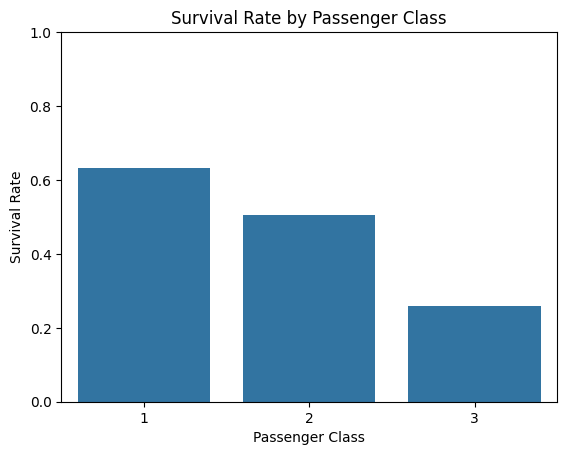

In [17]:
survival_by_class = titanic.groupby('pclass')['survived'].mean().reset_index()

sns.barplot(
    data=survival_by_class,
    x='pclass',
    y='survived'
)

plt.title('Survival Rate by Passenger Class')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.ylim(0, 1)

plt.show()

## Who had the advantage? Gender × Class [Grouped Bar chart]

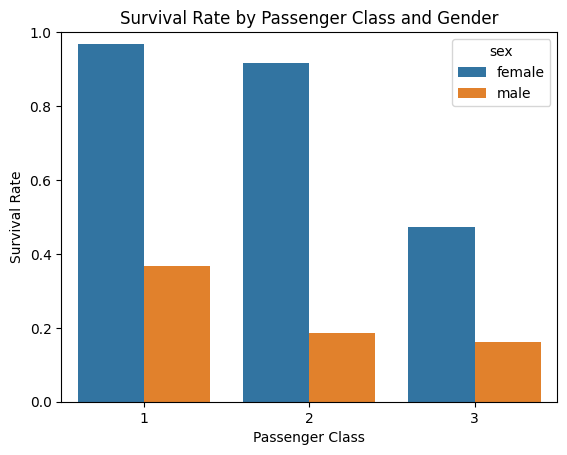

In [18]:
survival_gender_class = (
    titanic.groupby(['pclass', 'sex'])['survived']
    .mean()
    .reset_index()
)

sns.barplot(
    data=survival_gender_class,
    x='pclass',
    y='survived',
    hue='sex'
)

plt.title('Survival Rate by Passenger Class and Gender')
plt.xlabel('Passenger Class')
plt.ylabel('Survival Rate')
plt.ylim(0, 1)

plt.show()

## Family Size vs Survival [Line Chart]

In [19]:
titanic['family_size'] = titanic['sibsp'] + titanic['parch'] + 1

In [20]:
family_survival = (
    titanic.groupby('family_size')['survived']
    .mean()
    .reset_index()
)

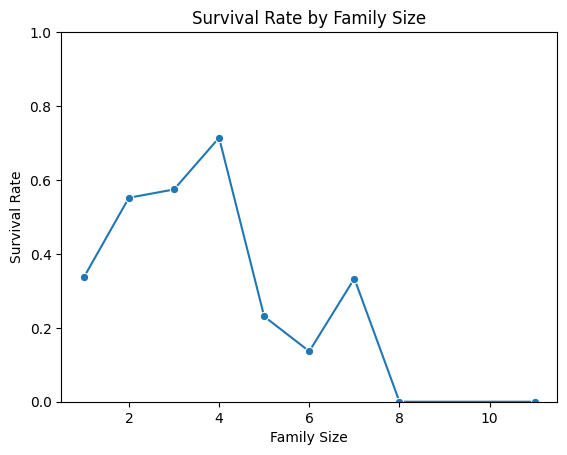

In [21]:
sns.lineplot(
    data=family_survival,
    x='family_size',
    y='survived',
    marker='o'
)

plt.title('Survival Rate by Family Size')
plt.xlabel('Family Size')
plt.ylabel('Survival Rate')
plt.ylim(0, 1)

plt.show()

## Age Distribution of Titanic Passengers [Histogram]

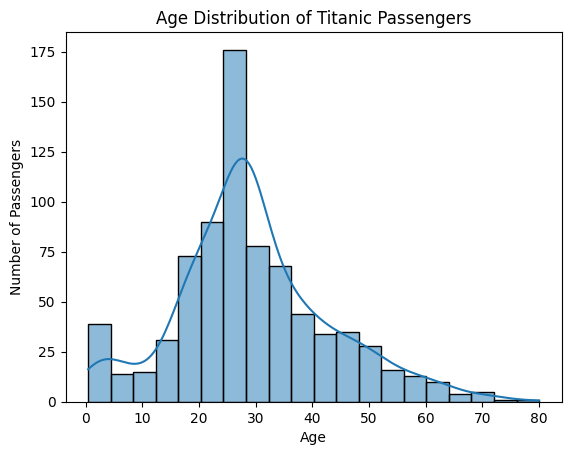

In [22]:
sns.histplot(
    data=titanic,
    x='age',
    bins=20,
    kde=True
)

plt.title('Age Distribution of Titanic Passengers')
plt.xlabel('Age')
plt.ylabel('Number of Passengers')

plt.show()

## Age Distribution by Survival Status [KDE Plot]

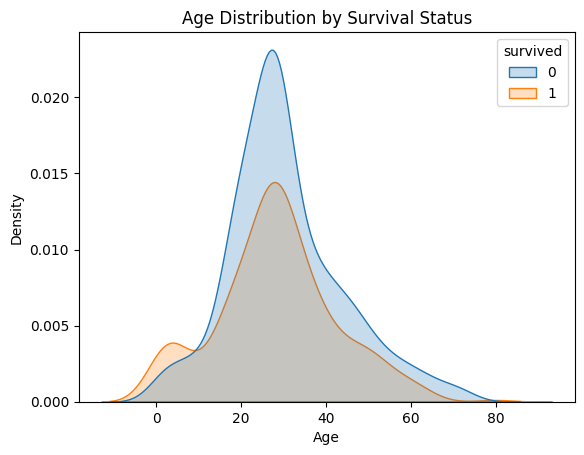

In [23]:
sns.kdeplot(
    data=titanic,
    x='age',
    hue='survived',
    fill=True
)

plt.title('Age Distribution by Survival Status')
plt.xlabel('Age')
plt.ylabel('Density')

plt.show()

## Fare Distribution Across Passenger Classes [box plot]

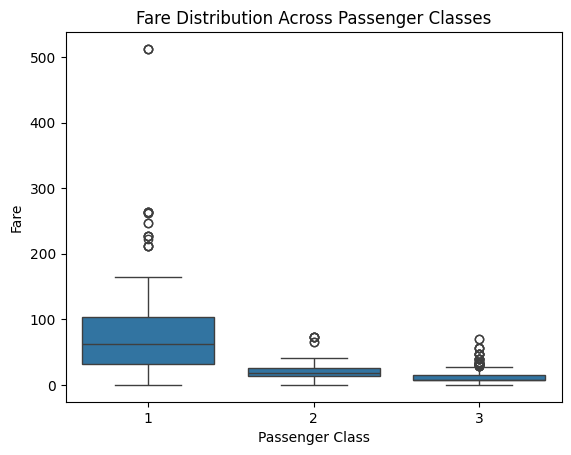

In [24]:
sns.boxplot(
    data=titanic,
    x='pclass',
    y='fare'
)

plt.title('Fare Distribution Across Passenger Classes')
plt.xlabel('Passenger Class')
plt.ylabel('Fare')

plt.show()

## Age Distribution by Gender and Survival [Violet Plot]

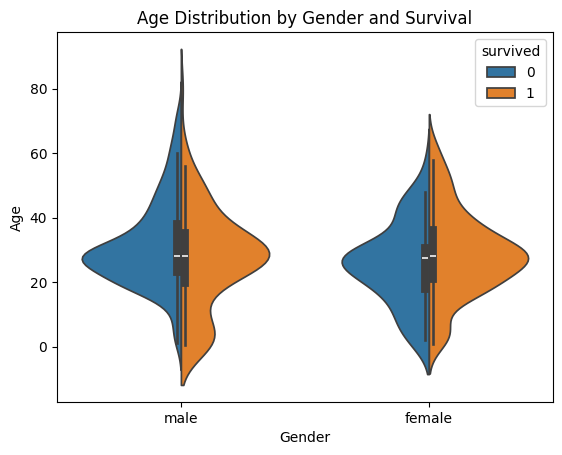

In [25]:
sns.violinplot(
    data=titanic,
    x='sex',
    y='age',
    hue='survived',
    split=True
)

plt.title('Age Distribution by Gender and Survival')
plt.xlabel('Gender')
plt.ylabel('Age')

plt.show()

## Relationship Between Age and Fare [Scatter plot]

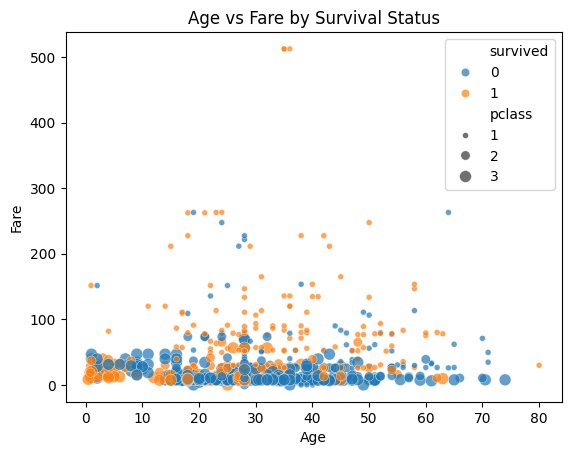

In [26]:
sns.scatterplot(
    data=titanic,
    x='age',
    y='fare',
    hue='survived',
    size='pclass',
    alpha=0.7
)

plt.title('Age vs Fare by Survival Status')
plt.xlabel('Age')
plt.ylabel('Fare')

plt.show()

## Correlation Heatmap

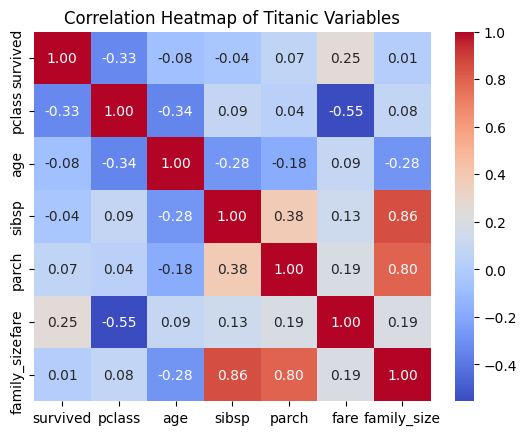

In [27]:
correlation = titanic[['survived', 'pclass', 'age', 'sibsp', 'parch', 'fare', 'family_size']].corr()

sns.heatmap(
    correlation,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Titanic Variables')
plt.show()